# Dry Bean Classification — Training & Evaluation of 5 ML Models

**Course assignment:** ML Classification Models & Streamlit Deployment

This notebook:
1. Loads the UCI Dry Bean dataset (13,611 beans, 16 shape features, 7 classes)
2. Cleans it (drops exact duplicate rows) and makes a stratified 80/20 train/test split
3. Trains 5 classifiers: Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM
4. Evaluates each on the held-out test set with Accuracy, AUC, Precision, Recall, F1 and MCC
5. Saves the trained models to `model/` and the test split to `test_data.csv` for the Streamlit app

In [2]:
import json
import platform
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)  # SVC(probability=True) notice in newest sklearn

SEED = 21
TARGET = "Class"
DATA_PATH = Path("data/Dry_Bean_Dataset.csv")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

print("Python      :", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("pandas      :", pd.__version__, "| numpy:", np.__version__)

Python      : 3.12.7
scikit-learn: 1.9.1
pandas      : 2.2.3 | numpy: 2.5.4


## 1. Load and inspect the data

In [4]:
beans = pd.read_csv(DATA_PATH)
print("Shape:", beans.shape)
print("Missing values:", int(beans.isna().sum().sum()))
print("Duplicate rows:", int(beans.duplicated().sum()))
beans.head()

Shape: (13611, 17)
Missing values: 0
Duplicate rows: 68


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395.0,610.291,208.178117,173.888747,1.197191,0.549812,28715.0,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734.0,638.018,200.524796,182.734419,1.097356,0.411785,29172.0,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380.0,624.110,212.826130,175.931143,1.209713,0.562727,29690.0,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008.0,645.884,210.557999,182.516516,1.153638,0.498616,30724.0,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140.0,620.134,201.847882,190.279279,1.060798,0.333680,30417.0,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


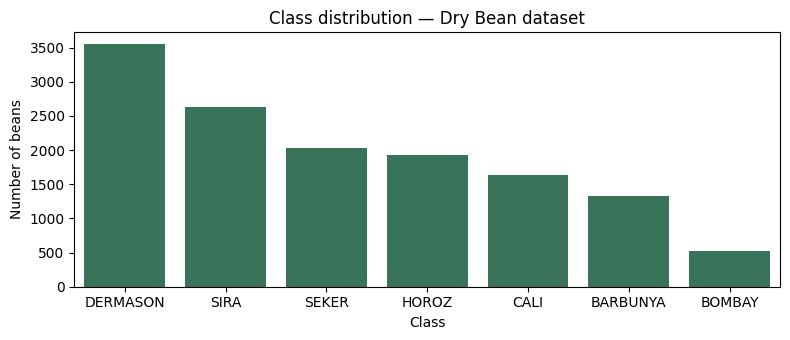

In [5]:
class_counts = beans[TARGET].value_counts()
print(class_counts)
plt.figure(figsize=(8, 3.5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="#2E7D5B")
plt.title("Class distribution — Dry Bean dataset")
plt.ylabel("Number of beans")
plt.tight_layout()
plt.show()

## 2. Clean and split

* 68 rows are exact duplicates. They are dropped so the same bean cannot appear in both
  the training set and the test set (that would inflate the scores).
* Stratified 80/20 split keeps the class proportions identical in train and test
  (important because BOMBAY is only ~4% of the data).

In [7]:
beans = beans.drop_duplicates().reset_index(drop=True)
feature_cols = [c for c in beans.columns if c != TARGET]
X = beans[feature_cols]
y = beans[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("After dropping duplicates:", beans.shape)
print("Features used:", len(feature_cols))
print("Train size:", X_train.shape, "| Test size:", X_test.shape)

# Save the untouched test split (features + target) for the Streamlit app
test_df = X_test.copy()
test_df[TARGET] = y_test.values
test_df.to_csv("test_data.csv", index=False)
print("Saved test_data.csv with", len(test_df), "rows")

After dropping duplicates: (13543, 17)
Features used: 16
Train size: (10834, 16) | Test size: (2709, 16)
Saved test_data.csv with 2709 rows


## 3. Define the 5 models

Scale-sensitive models (Logistic Regression, KNN, SVM) are wrapped in a `Pipeline`
with a `StandardScaler`, so the scaler is fitted only on training data and is saved
**inside** the model file. The Streamlit app can then feed raw test features directly.

Small hyper-parameter grids are tuned with 5-fold stratified cross-validation
on the **training set only** (the test set is never seen during tuning).

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

candidates = {
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=5000, random_state=SEED))]),
        {"clf__C": [0.1, 1, 10]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"max_depth": [6, 8, 10, 12, None], "min_samples_leaf": [1, 5, 10]}),
    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [3, 5, 7, 9, 11, 15], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (
        GaussianNB(),
        {}),
    "Support Vector Machine": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", SVC(kernel="rbf", probability=True, random_state=SEED))]),
        {"clf__C": [1, 10, 50]}),
}

file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib",
}

## 4. Evaluation metrics

The problem has 7 classes, so:
* **Precision, Recall, F1** use the **weighted** average (each class weighted by its number of test samples).
* **AUC** is the one-vs-rest ROC AUC, weighted the same way, computed from predicted probabilities.
* **MCC** uses the multi-class generalisation built into scikit-learn.

In [11]:
def evaluate(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    return {
        "Accuracy": accuracy_score(y_eval, y_pred),
        "AUC": roc_auc_score(y_eval, y_proba, multi_class="ovr", average="weighted",
                             labels=model.classes_),
        "Precision": precision_score(y_eval, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_eval, y_pred, average="weighted", zero_division=0),
        "F1": f1_score(y_eval, y_pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y_eval, y_pred),
    }

## 5. Train, tune, evaluate and save

In [13]:
results, best_params, trained = {}, {}, {}

for name, (estimator, grid) in candidates.items():
    start = time.time()
    if grid:
        search = GridSearchCV(estimator, grid, cv=cv, scoring="accuracy", n_jobs=-1)
        search.fit(X_train, y_train)
        model = search.best_estimator_
        best_params[name] = search.best_params_
    else:
        model = estimator.fit(X_train, y_train)
        best_params[name] = {}
    trained[name] = model
    results[name] = evaluate(model, X_test, y_test)
    joblib.dump(model, MODEL_DIR / file_names[name])
    print(f"{name:<24} done in {time.time() - start:5.1f}s | best params: {best_params[name]}")

Logistic Regression      done in   8.8s | best params: {'clf__C': 1}
Decision Tree            done in   5.0s | best params: {'max_depth': 8, 'min_samples_leaf': 10}
KNN                      done in   6.0s | best params: {'clf__n_neighbors': 9, 'clf__weights': 'distance'}
Naive Bayes              done in   0.2s | best params: {}
Support Vector Machine   done in  30.8s | best params: {'clf__C': 10}


In [14]:
metrics_df = pd.DataFrame(results).T[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]]
metrics_df.index.name = "ML Model Name"
print("Test-set results (n =", len(y_test), ")")
metrics_df.round(4)

Test-set results (n = 2709 )


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9228,0.9945,0.9232,0.9228,0.9230,0.9067
Decision Tree,0.9140,0.9859,0.9164,0.9140,0.9146,0.8963
KNN,0.9247,0.9898,0.9252,0.9247,0.9248,0.9089
Naive Bayes,0.7630,0.9650,0.7632,0.7630,0.7611,0.7140
Support Vector Machine,0.9350,0.9955,0.9352,0.9350,0.9351,0.9214


## 6. Visual comparison

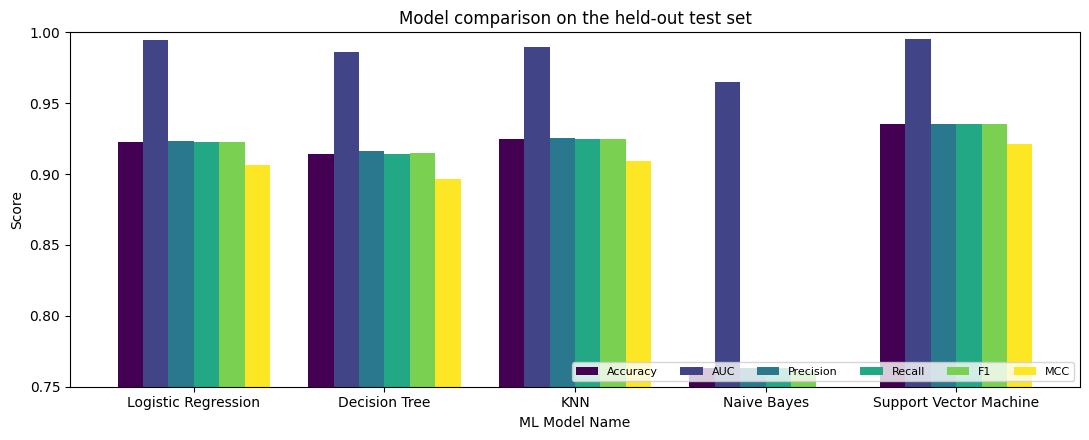

In [16]:
ax = metrics_df.plot(kind="bar", figsize=(11, 4.5), width=0.8, colormap="viridis")
ax.set_ylim(0.75, 1.0)
ax.set_title("Model comparison on the held-out test set")
ax.set_ylabel("Score")
ax.legend(loc="lower right", ncol=6, fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

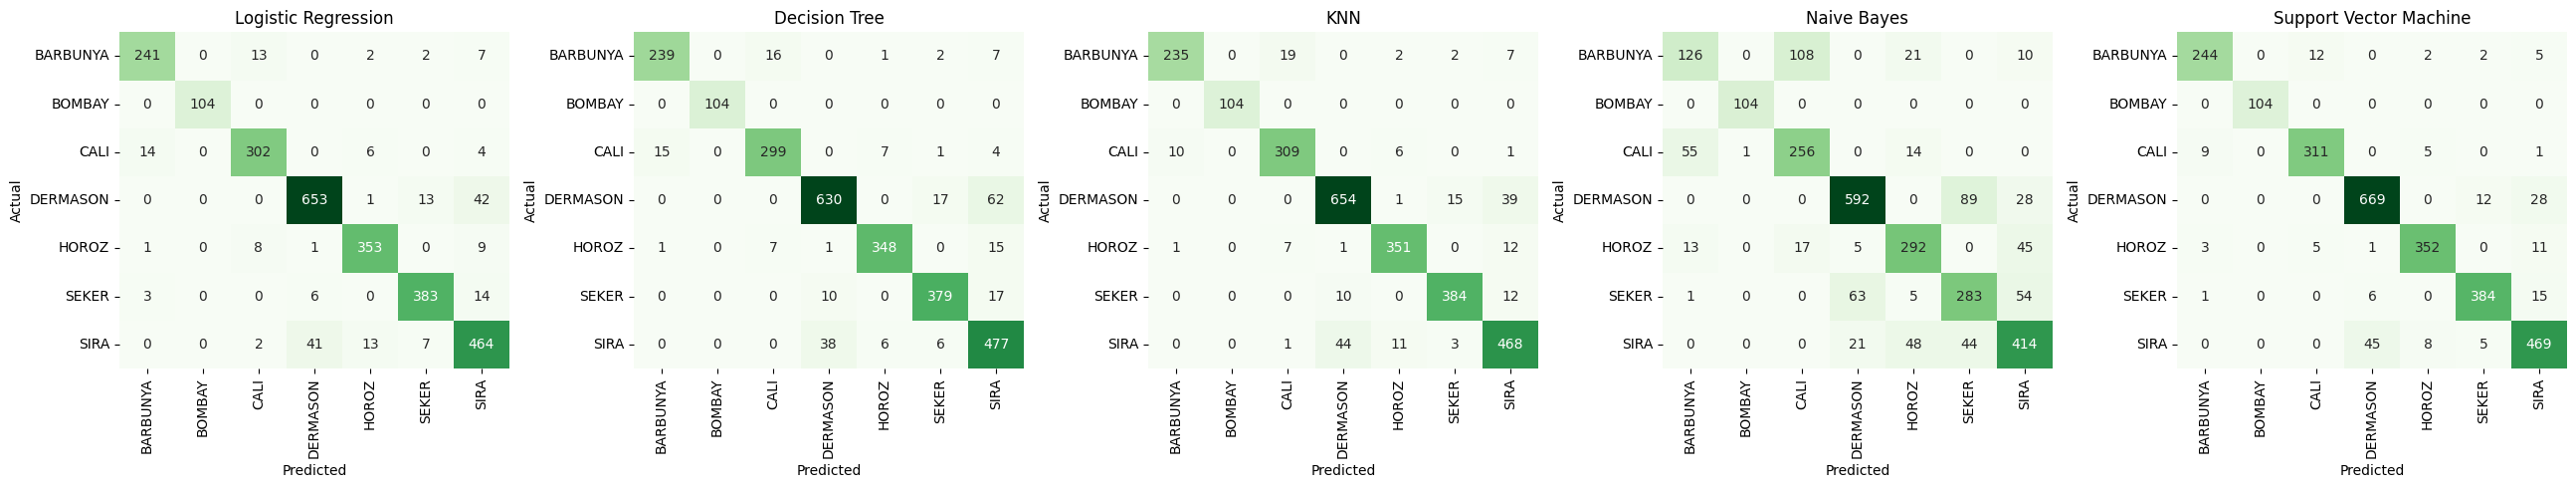

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(26, 5))
for ax, (name, model) in zip(axes, trained.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=model.classes_)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax,
                xticklabels=model.classes_, yticklabels=model.classes_)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [18]:
best_name = metrics_df["Accuracy"].idxmax()
print("Best model by accuracy:", best_name)
print(classification_report(y_test, trained[best_name].predict(X_test), digits=4))

Best model by accuracy: Support Vector Machine
              precision    recall  f1-score   support

    BARBUNYA     0.9494    0.9208    0.9349       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9482    0.9540    0.9511       326
    DERMASON     0.9279    0.9436    0.9357       709
       HOROZ     0.9591    0.9462    0.9526       372
       SEKER     0.9529    0.9458    0.9493       406
        SIRA     0.8866    0.8899    0.8883       527

    accuracy                         0.9350      2709
   macro avg     0.9463    0.9429    0.9445      2709
weighted avg     0.9352    0.9350    0.9351      2709



## 7. Save metadata used by the Streamlit app

In [20]:
meta = {
    "dataset": "UCI Dry Bean Dataset (id 602)",
    "target": TARGET,
    "feature_columns": feature_cols,
    "classes": list(trained["Logistic Regression"].classes_),
    "model_files": file_names,
    "best_params": {k: {p: (v if v is None or isinstance(v, (int, float, str)) else str(v))
                        for p, v in d.items()} for k, d in best_params.items()},
    "test_metrics": metrics_df.round(4).to_dict(orient="index"),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "random_state": SEED,
    "sklearn_version": sklearn.__version__,
}
with open(MODEL_DIR / "model_info.json", "w") as f:
    json.dump(meta, f, indent=2)

print(sorted(p.name for p in MODEL_DIR.iterdir()))

['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'model_info.json', 'naive_bayes.joblib', 'svm.joblib']
